# Verifying the LLC4320 v2 HOWTO against the live bucket

Companion to <https://wrangler.readthedocs.io/en/llc4320_v2/howto/llc4320_v2.html>.

Every factual statement in the HOWTO becomes one check below, in the HOWTO's own
order. Each check prints **PASS / FAIL / INFO** with the measured value next to the
documented one, and everything is collected in a summary table at the end
(Section 12). Nothing is hidden behind a helper: the code that produces each
number is in the cell above it.

Two things this notebook also establishes for the repo:

* the v2 bucket can be read with the **same `dbof` modules** we use for the original
  LLC4320 stores (`dbof.llc4320_ingestion.get_raw_data`, `grid`, `native_gradient`),
  and exactly which call-site changes are needed (Section 7);
* the **vertical axis** of v2 (173 levels) versus what the repo currently assumes
  (top 51 of 90), so the future DEPTH work knows what is coming (Section 11).

Run in the `ocean14` environment. Only Section 8 needs `wrangler`; it is skipped
cleanly if the package is absent. Total data read is a few GB.

In [1]:
import time, re
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import xarray as xr
import zarr, s3fs, dask
import matplotlib.pyplot as plt

print("xarray", xr.__version__, "| zarr", zarr.__version__, "| s3fs", s3fs.__version__, "| dask", dask.__version__)
assert int(zarr.__version__.split(".")[0]) >= 3, "HOWTO requires zarr 3+"

xarray 2025.10.1 | zarr 3.1.5 | s3fs 2025.9.0 | dask 2025.10.0


In [2]:
# --- exactly as in the HOWTO ("Reading it with xarray alone") -----------------
ENDPOINT = "https://s3-west.nrp-nautilus.io"
BUCKET   = "llc4320-v2"
PREFIX   = "SURFACE"
ROOT     = f"s3://{BUCKET}/{PREFIX}"

OPTS = {"anon": True,
        "client_kwargs": {"endpoint_url": ENDPOINT},
        "config_kwargs": {"s3": {"addressing_style": "path"}}}

# --- a tiny PASS/FAIL ledger so the summary table at the end is honest ---------
RESULTS = []

def check(section, claim, observed, expected=None, ok=None, note=""):
    '''Record one HOWTO claim.  ok=None -> INFO (no pass/fail asserted).'''
    if ok is None and expected is not None:
        ok = observed == expected
    status = "INFO" if ok is None else ("PASS" if ok else "FAIL")
    RESULTS.append(dict(section=section, claim=claim, status=status,
                        documented=expected, observed=observed, note=note))
    print(f"[{status}] {claim}: observed={observed!r}" + (f"  documented={expected!r}" if expected is not None else "") + (f"  ({note})" if note else ""))
    return ok

## 1. Access — anonymous, read-only, path-style

HOWTO: endpoint `https://s3-west.nrp-nautilus.io`, bucket `s3://llc4320-v2/SURFACE`,
no credentials, read-only, Ceph needs path-style addressing.

In [3]:
fs = s3fs.S3FileSystem(**OPTS)

t0 = time.time()
entries = fs.ls(ROOT, detail=False)
print(f"listed {len(entries)} objects under {ROOT} in {time.time()-t0:.1f}s")

names = sorted(e.rsplit("/", 1)[-1] for e in entries)
hourly = [n for n in names if re.fullmatch(r"\d{8}T\d{2}\.zarr", n)]
other  = [n for n in names if n not in hourly]

check(1, "anonymous listing works", True, True)
check(1, "grid.zarr present", "grid.zarr" in names, True)
check(1, "non-hourly objects in prefix", other, note="expect only grid.zarr")

listed 9503 objects under s3://llc4320-v2/SURFACE in 3.6s
[PASS] anonymous listing works: observed=True  documented=True
[PASS] grid.zarr present: observed=True  documented=True
[INFO] non-hourly objects in prefix: observed=['grid.zarr']  (expect only grid.zarr)


In [4]:
# Read-only: a write must be refused.  (A PASS here means the bucket rejected us.)
try:
    with fs.open(f"{ROOT}/_write_probe_from_dbof_notebook.txt", "wb") as f:
        f.write(b"probe")
    writable = True
    fs.rm(f"{ROOT}/_write_probe_from_dbof_notebook.txt")
except Exception as e:
    writable = False
    print("write refused:", type(e).__name__)
check(1, "bucket is read-only for anonymous clients", not writable, True)

write refused: PermissionError
[PASS] bucket is read-only for anonymous clients: observed=True  documented=True


True

In [5]:
# Path-style is required: the same request with virtual-hosted addressing should fail.
OPTS_VHOST = {"anon": True, "client_kwargs": {"endpoint_url": ENDPOINT},
              "config_kwargs": {"s3": {"addressing_style": "virtual"}}}
try:
    s3fs.S3FileSystem(**OPTS_VHOST).ls(ROOT)
    vhost_ok = True
except Exception as e:
    vhost_ok = False
    print("virtual-hosted addressing failed as expected:", type(e).__name__)
check(1, "path-style addressing is required (virtual-hosted fails)", not vhost_ok, True,
      note="INFO only if your DNS happens to resolve bucket.host")

virtual-hosted addressing failed as expected: OSError
[PASS] path-style addressing is required (virtual-hosted fails): observed=True  documented=True  (INFO only if your DNS happens to resolve bucket.host)


True

## 2. Coverage — 2023-01-01 01:00 → 2024-02-08 20:00 UTC, hourly, 9 692 stores, no gaps

Derived purely from the store names (`YYYYMMDDTHH.zarr`), which the HOWTO says
are the UTC timestamps.

In [6]:
stamps = pd.to_datetime([n[:-5] for n in hourly], format="%Y%m%dT%H", utc=True).sort_values()
expected_index = pd.date_range(stamps[0], stamps[-1], freq="1h", tz="UTC")
missing = expected_index.difference(stamps)
dups    = stamps[stamps.duplicated()]

check(2, "number of hourly stores", len(hourly), 9692)
check(2, "first snapshot (UTC)", str(stamps[0]), "2023-01-01 01:00:00+00:00")
check(2, "last snapshot (UTC)",  str(stamps[-1]), "2024-02-08 20:00:00+00:00")
check(2, "hourly, no gaps", len(missing) == 0 and len(dups) == 0, True,
      note=f"{len(missing)} missing, {len(dups)} duplicate")
if len(missing):
    print("missing hours:", list(missing[:20]), "..." if len(missing) > 20 else "")

[FAIL] number of hourly stores: observed=9502  documented=9692
[PASS] first snapshot (UTC): observed='2023-01-01 01:00:00+00:00'  documented='2023-01-01 01:00:00+00:00'
[FAIL] last snapshot (UTC): observed='2024-01-31 23:00:00+00:00'  documented='2024-02-08 20:00:00+00:00'
[FAIL] hourly, no gaps: observed=False  documented=True  (1 missing, 0 duplicate)
missing hours: [Timestamp('2023-10-19 03:00:00+0000', tz='UTC')] 


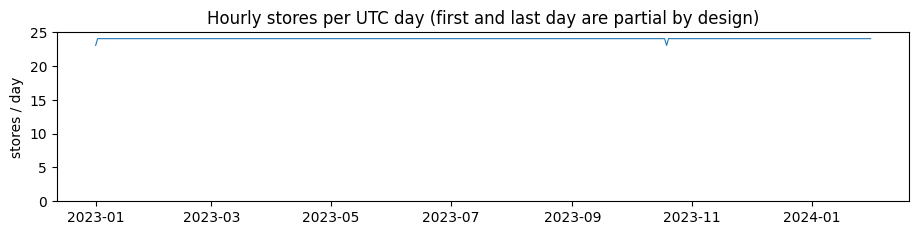

In [7]:
# Hours-per-day histogram: a flat 24 everywhere is the visual version of "no gaps".
per_day = pd.Series(1, index=stamps).resample("1D").sum()
fig, ax = plt.subplots(figsize=(11, 2.2))
ax.plot(per_day.index, per_day.values, lw=0.8)
ax.set_ylim(0, 25); ax.set_ylabel("stores / day")
ax.set_title("Hourly stores per UTC day (first and last day are partial by design)")
plt.show()

## 3. One hourly store — layout, shape, dtype, chunks, attributes

HOWTO: `Theta` dimensioned `(face, j, i)` = (13, 4320, 4320), float32, chunks
`(1, 720, 720)`, no time axis, ~470 MB per hour, land = NaN, stores carry
`face_layout = "llc_faces"` and provenance attributes
`selected_date_utc`, `selected_iteration`, `source_folder`, `source_file`.
Metadata is consolidated (open should cost one or two requests).

In [8]:
STORE = f"{ROOT}/20230301T06.zarr"      # the HOWTO's example hour

t0 = time.time()
ds = xr.open_zarr(STORE, storage_options=OPTS)
t_open = time.time() - t0
print(f"opened in {t_open:.2f}s\n")
ds

opened in 0.98s



<xarray.Dataset> Size: 971MB
Dimensions:  (face: 13, j: 4320, i: 4320)
Coordinates:
  * face     (face) int64 104B 0 1 2 3 4 5 6 7 8 9 10 11 12
  * j        (j) int64 35kB 0 1 2 3 4 5 6 ... 4313 4314 4315 4316 4317 4318 4319
  * i        (i) int64 35kB 0 1 2 3 4 5 6 ... 4313 4314 4315 4316 4317 4318 4319
Data variables:
    Theta    (face, j, i) float32 970MB dask.array<chunksize=(1, 720, 720), meta=np.ndarray>
Attributes:
    model:               LLC4320_v2
    selected_iteration:  263400
    selected_date_utc:   2023-03-01 06:00:00
    source_folder:       2023_02_28_150000_to_2023_03_03_170000
    FS:                  4320
    variables:           ['Theta']
    complete:            True
    face_layout:         llc_faces

In [9]:
th = ds.Theta
check(3, "Theta dims", tuple(th.dims), ("face", "j", "i"))
check(3, "Theta shape", tuple(th.shape), (13, 4320, 4320))
check(3, "Theta dtype", str(th.dtype), "float32")
check(3, "on-disk chunks (face, j, i)", tuple(c[0] for c in th.chunks), (1, 720, 720))
check(3, "no time dimension", "time" not in ds.dims, True)
check(3, "face_layout attr", ds.attrs.get("face_layout", th.attrs.get("face_layout")), "llc_faces")
for a in ["selected_date_utc", "selected_iteration", "source_folder", "source_file"]:
    val = ds.attrs.get(a, th.attrs.get(a))
    check(3, f"attribute '{a}' present", val, ok=val is not None)
check(3, "in-memory size per hour (MB)", round(th.nbytes / 1e6), 970, note="13*4320*4320*4 B; HOWTO's 470 MB is on disk, measured next")
# on-disk size: sum of stored object sizes (compressed, land tiles absent)
disk_mb = sum(fs.du(f"{STORE}/Theta", total=False).values()) / 1e6
check(3, "on-disk size per hour (MB)", round(disk_mb), ok=abs(disk_mb - 470) < 60, expected=470)
check(3, "store open time (s)  — consolidated metadata", round(t_open, 2),
      ok=t_open < 5, note="one or two HTTP requests expected")

[PASS] Theta dims: observed=('face', 'j', 'i')  documented=('face', 'j', 'i')
[PASS] Theta shape: observed=(13, 4320, 4320)  documented=(13, 4320, 4320)
[PASS] Theta dtype: observed='float32'  documented='float32'
[PASS] on-disk chunks (face, j, i): observed=(1, 720, 720)  documented=(1, 720, 720)
[PASS] no time dimension: observed=True  documented=True
[PASS] face_layout attr: observed='llc_faces'  documented='llc_faces'
[PASS] attribute 'selected_date_utc' present: observed='2023-03-01 06:00:00'
[PASS] attribute 'selected_iteration' present: observed=263400
[PASS] attribute 'source_folder' present: observed='2023_02_28_150000_to_2023_03_03_170000'
[PASS] attribute 'source_file' present: observed='SST.0000263400.data'
[PASS] in-memory size per hour (MB): observed=970  documented=970  (13*4320*4320*4 B; HOWTO's 470 MB is on disk, measured next)
[PASS] on-disk size per hour (MB): observed=463  documented=470
[PASS] store open time (s)  — consolidated metadata: observed=0.98  (one or two

True

In [10]:
# The time stamp in the store name and the one in the attributes must agree.
sel = ds.attrs.get("selected_date_utc")
check(3, "store name == selected_date_utc",
      pd.Timestamp(sel).strftime("%Y%m%dT%H") if sel else None, "20230301T06")

[PASS] store name == selected_date_utc: observed='20230301T06'  documented='20230301T06'


True

In [11]:
# Consolidated metadata: inspect what zarr actually finds at the root.
root = zarr.open_group(STORE, mode="r", storage_options=OPTS)
print("zarr format:", root.metadata.zarr_format)
print("arrays:", list(root.array_keys()))
print("root attrs keys:", sorted(root.attrs.keys()))
has_consolidated = getattr(root.metadata, "consolidated_metadata", None) is not None
check(3, "consolidated metadata present", has_consolidated, True)

zarr format: 3
arrays: ['face', 'i', 'j', 'Theta']
root attrs keys: ['FS', 'complete', 'face_layout', 'model', 'selected_date_utc', 'selected_iteration', 'source_folder', 'variables']
[PASS] consolidated metadata present: observed=True  documented=True


True

## 4. `grid.zarr` — 23 static variables, 173 levels

HOWTO lists: geometry `XC YC XG YG rA rAs rAw rAz dxC dyC dxG dyG`;
bathymetry/masks `Depth maskC hFacC_k0 hFacS_k0 hFacW_k0`; rotation `CS SN`;
vertical `RC DRF` (173 levels) and `RF DRC` (174 interfaces).
The HOWTO also says to use **this** `grid.zarr`, not the earlier run's.

In [12]:
grid = xr.open_zarr(f"{ROOT}/grid.zarr", storage_options=OPTS)

HOWTO_GRID_VARS = {
    "geometry":   ["XC", "YC", "XG", "YG", "rA", "rAs", "rAw", "rAz", "dxC", "dyC", "dxG", "dyG"],
    "bathy/mask": ["Depth", "maskC", "hFacC_k0", "hFacS_k0", "hFacW_k0"],
    "rotation":   ["CS", "SN"],
    "vertical":   ["RC", "DRF", "RF", "DRC"],
}
documented = sorted(v for vs in HOWTO_GRID_VARS.values() for v in vs)
present    = sorted(set(grid.data_vars) | set(grid.coords))

check(4, "number of grid variables (data_vars)", len(grid.data_vars), 23)
check(4, "all documented variables present", sorted(set(documented) - set(present)), [],
      note="list = documented-but-missing")
check(4, "undocumented extras", sorted(set(grid.data_vars) - set(documented)), [])
grid

[PASS] number of grid variables (data_vars): observed=23  documented=23
[PASS] all documented variables present: observed=[]  documented=[]  (list = documented-but-missing)
[PASS] undocumented extras: observed=[]  documented=[]


<xarray.Dataset> Size: 18GB
Dimensions:   (face: 13, j: 4320, i: 4320, k_p1: 174, k: 173)
Coordinates:
  * face      (face) int64 104B 0 1 2 3 4 5 6 7 8 9 10 11 12
  * j         (j) int64 35kB 0 1 2 3 4 5 6 ... 4314 4315 4316 4317 4318 4319
  * i         (i) int64 35kB 0 1 2 3 4 5 6 ... 4314 4315 4316 4317 4318 4319
Dimensions without coordinates: k_p1, k
Data variables: (12/23)
    CS        (face, j, i) float32 970MB dask.array<chunksize=(1, 720, 720), meta=np.ndarray>
    Depth     (face, j, i) float32 970MB dask.array<chunksize=(1, 720, 720), meta=np.ndarray>
    DRC       (k_p1) float32 696B dask.array<chunksize=(174,), meta=np.ndarray>
    DRF       (k) float32 692B dask.array<chunksize=(173,), meta=np.ndarray>
    dxC       (face, j, i) float32 970MB dask.array<chunksize=(1, 720, 720), meta=np.ndarray>
    dxG       (face, j, i) float32 970MB dask.array<chunksize=(1, 720, 720), meta=np.ndarray>
    ...        ...
    RF        (k_p1) float32 696B dask.array<chunksize=(174,), meta=np.ndarray>
    SN        (face, j, i) float32 970MB dask.array<chunksize=(1, 720, 720), meta=np.ndarray>
    XC        (face, j, i) float32 970MB dask.array<chunksize=(1, 720, 720), meta=np.ndarray>
    XG        (face, j, i) float32 970MB dask.array<chunksize=(1, 720, 720), meta=np.ndarray>
    YC        (face, j, i) float32 970MB dask.array<chunksize=(1, 720, 720), meta=np.ndarray>
    YG        (face, j, i) float32 970MB dask.array<chunksize=(1, 720, 720), meta=np.ndarray>
Attributes:
    model:        LLC4320_v2
    FS:           4320
    complete:     True
    face_layout:  llc_faces
    grid_dir:     /nobackupp27/dbwhitt/llc_4320/grid_90x90x19493
    mask_dir:     /nobackupp29/bcnelson/MITgcm/compressedOutput/work/bitmask....
    description:  Static grid information for LLC4320 v2 surface output (see ...
    variables:    ['XC', 'YC', 'XG', 'YG', 'rA', 'rAs', 'rAw', 'rAz', 'dxC', ...
    skipped:      []

In [13]:
# Dimensions and shapes, one line per variable — this is what the pipeline code keys on.
rows = [(v, grid[v].dims, grid[v].shape, str(grid[v].dtype)) for v in grid.data_vars]
pd.DataFrame(rows, columns=["var", "dims", "shape", "dtype"]).set_index("var")

,dims,shape,dtype
var,,,
CS,"(face, j, i)","(13, 4320, 4320)",float32
Depth,"(face, j, i)","(13, 4320, 4320)",float32
DRC,"(k_p1,)","(174,)",float32
DRF,"(k,)","(173,)",float32
dxC,"(face, j, i)","(13, 4320, 4320)",float32
dxG,"(face, j, i)","(13, 4320, 4320)",float32
dyC,"(face, j, i)","(13, 4320, 4320)",float32
dyG,"(face, j, i)","(13, 4320, 4320)",float32
hFacC_k0,"(face, j, i)","(13, 4320, 4320)",float32


In [14]:
check(4, "RC length (cell centres)",  grid.RC.size, 173)
check(4, "DRF length",                grid.DRF.size, 173)
check(4, "RF length (interfaces)",    grid.RF.size, 174)
check(4, "DRC length",                grid.DRC.size, 174)

rc, rf, drf = grid.RC.values, grid.RF.values, grid.DRF.values
check(4, "RC monotonic (positive-up MITgcm convention → decreasing)", bool(np.all(np.diff(rc) < 0)), True)
check(4, "DRF == RF[k]-RF[k+1]", bool(np.allclose(drf, rf[:-1] - rf[1:], atol=1e-3)), True)
print(f"first centre {rc[0]:.3f} m, last centre {rc[-1]:.1f} m, bottom interface {rf[-1]:.1f} m")

[PASS] RC length (cell centres): observed=173  documented=173
[PASS] DRF length: observed=173  documented=173
[PASS] RF length (interfaces): observed=174  documented=174
[PASS] DRC length: observed=174  documented=174
[PASS] RC monotonic (positive-up MITgcm convention → decreasing): observed=True  documented=True
[PASS] DRF == RF[k]-RF[k+1]: observed=True  documented=True
first centre -1.816 m, last centre -7079.3 m, bottom interface -7192.0 m


## 5. Faces and rotation — `j` is not latitude on faces 7–12

HOWTO: faces 7–12 are rotated; take positions from `XC`/`YC`, never from indices.
We show this directly, then do the check the HOWTO does **not** do but the repo
needs: is the v2 horizontal grid *identical* to the original LLC4320 grid the
repo already uses (OSN kerchunk `llc4320_grid_f*.json`)? If it is, every face
connection, metric and rotation coefficient in `dbof.llc4320_ingestion.grid` carries
over unchanged.

In [15]:
XC, YC = grid.XC.compute(), grid.YC.compute()

# Along which index does latitude vary?  corr(YC, j) ≈ ±1 on unrotated faces,
# corr(YC, i) ≈ ±1 on rotated faces.
def _corr_with_index(da, dim):
    idx = xr.DataArray(np.arange(da.sizes[dim]), dims=dim).broadcast_like(da)
    return float(np.corrcoef(da.values.ravel(), idx.values.ravel())[0, 1])

rows = []
for f in range(13):
    yc = YC.isel(face=f)
    cj = abs(_corr_with_index(yc, "j")); ci = abs(_corr_with_index(yc, "i"))
    rows.append(dict(face=f, corr_lat_j=round(cj, 3), corr_lat_i=round(ci, 3),
                     lat_runs_along="j" if cj > ci else "i"))
tbl = pd.DataFrame(rows).set_index("face"); display(tbl)

rotated = set(tbl.index[tbl.lat_runs_along == "i"])
check(5, "faces where latitude runs along i (rotated)", sorted(rotated), [7, 8, 9, 10, 11, 12],
      note="face 6 is the Arctic cap; either answer is fine there")

,corr_lat_j,corr_lat_i,lat_runs_along
face,,,
0,0.976,0.111,j
1,0.997,0.000,j
2,0.993,0.000,j
3,0.967,0.120,j
4,0.997,0.000,j
5,0.993,0.000,j
6,0.000,0.000,j
7,0.000,0.993,i
8,0.000,0.997,i


[PASS] faces where latitude runs along i (rotated): observed=[7, 8, 9, 10, 11, 12]  documented=[7, 8, 9, 10, 11, 12]  (face 6 is the Arctic cap; either answer is fine there)


True

/Users/lahoffma/projects/Sea-Meets-the-Stars/llc4320-native-grid-preprocessing/src/dbof/plotting/llc_plotting.py:151: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


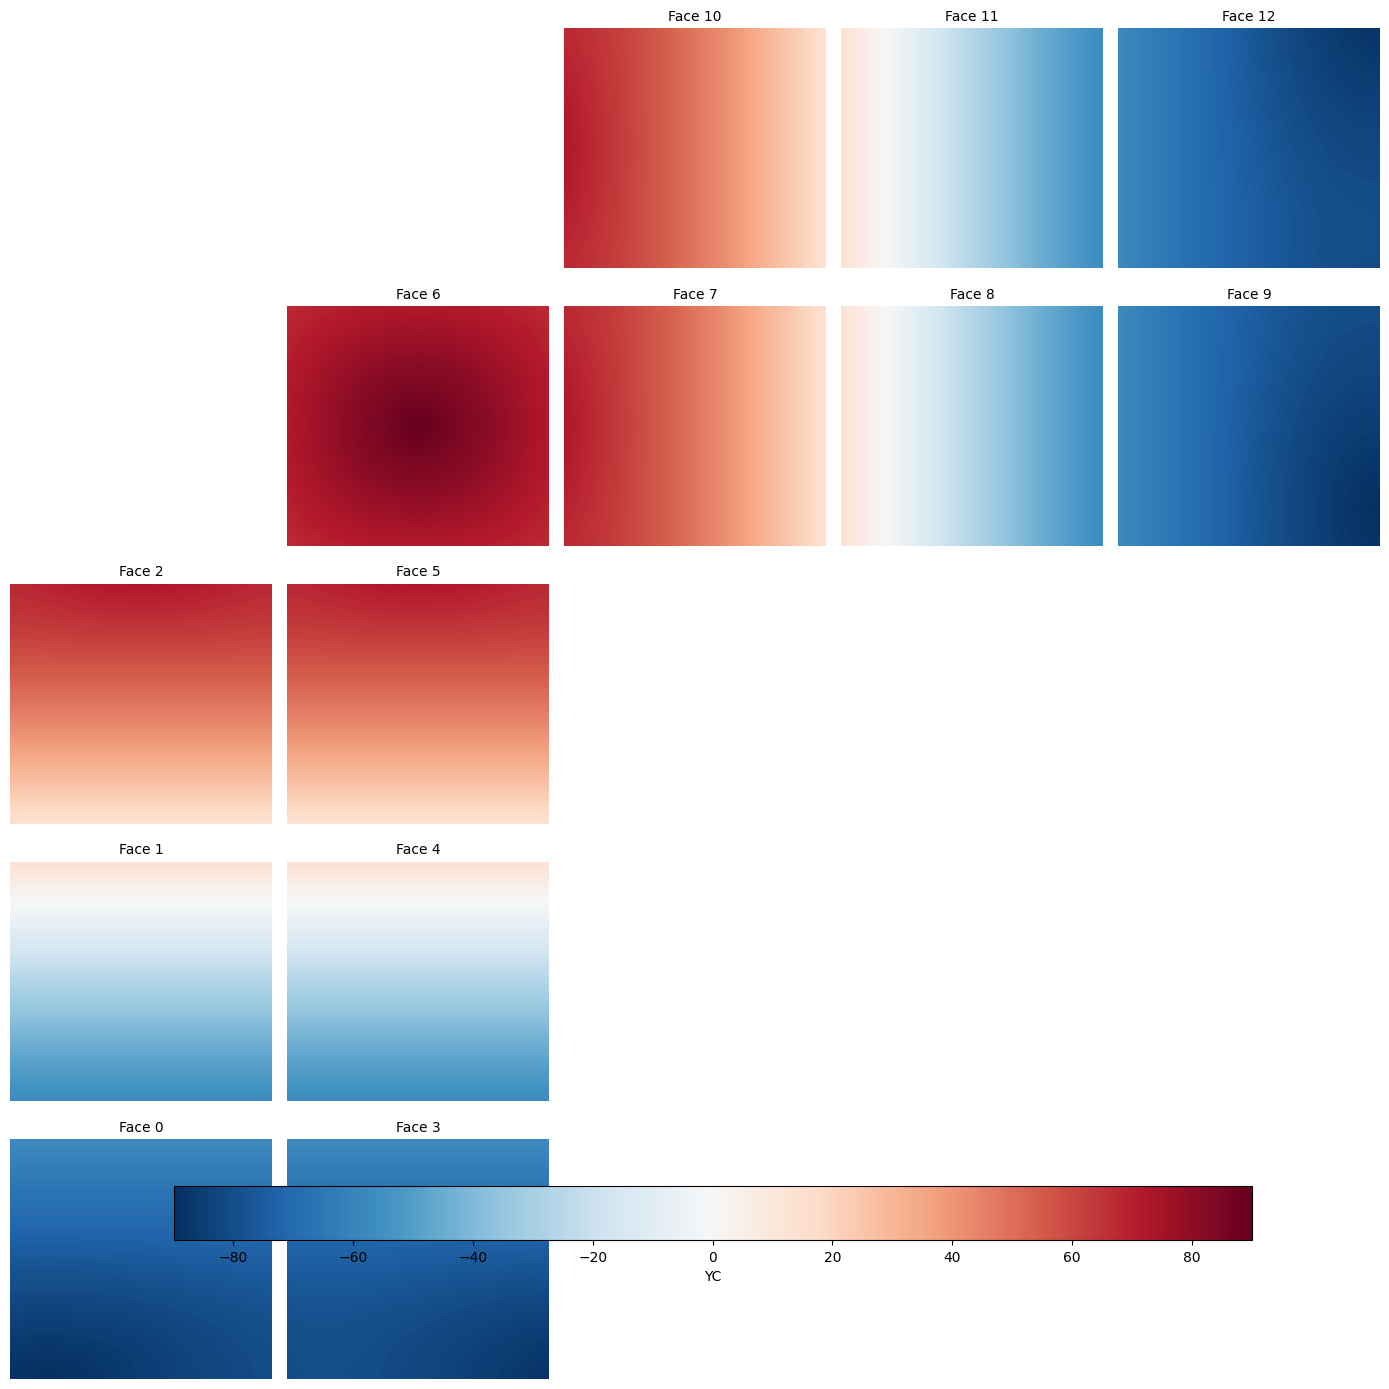

<Figure size 640x480 with 0 Axes>

In [16]:
# The classic 13-face layout, coloured by latitude, using the repo's own plotting helper.
from dbof.plotting import llc_plotting
llc_plotting.plot_llc_faces_layout(YC, color_map="RdBu_r", vmin=-90, vmax=90)
plt.suptitle("YC per face — rotated faces have latitude varying along i", y=0.92)
plt.show()

,max_abs_diff,note
var,,
XC,0.000000,
YC,0.000000,
Depth,3082.413574,
rA,0.000000,
dxC,0.000000,
dyC,0.000000,
dxG,0.000000,
dyG,0.000000,
rAz,0.000000,


[PASS] v2 XC/YC identical to original LLC4320 grid: observed=True  documented=True  (→ face_connections / COMODO metadata in dbof carry over unchanged)
[FAIL] v2 CS/SN identical to original LLC4320 grid (float32 tolerance): observed=1.0
[FAIL] v2 Depth identical to original: observed=3082.41357421875  (bathymetry is what differs if the v2 run used a different topography)
[INFO] cells where |Depth_v2 - Depth_v1| > 1 m: observed=140554194  (of 242611200; 57.934 %)
differing cells per face: {0: 7001258, 1: 14433073, 2: 8853036, 3: 4576507, 4: 16411510, 5: 2849812, 6: 12162389, 7: 13693901, 8: 17650530, 9: 10401940, 10: 8624596, 11: 14235891, 12: 9659751}


/Users/lahoffma/projects/Sea-Meets-the-Stars/llc4320-native-grid-preprocessing/src/dbof/plotting/llc_plotting.py:151: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


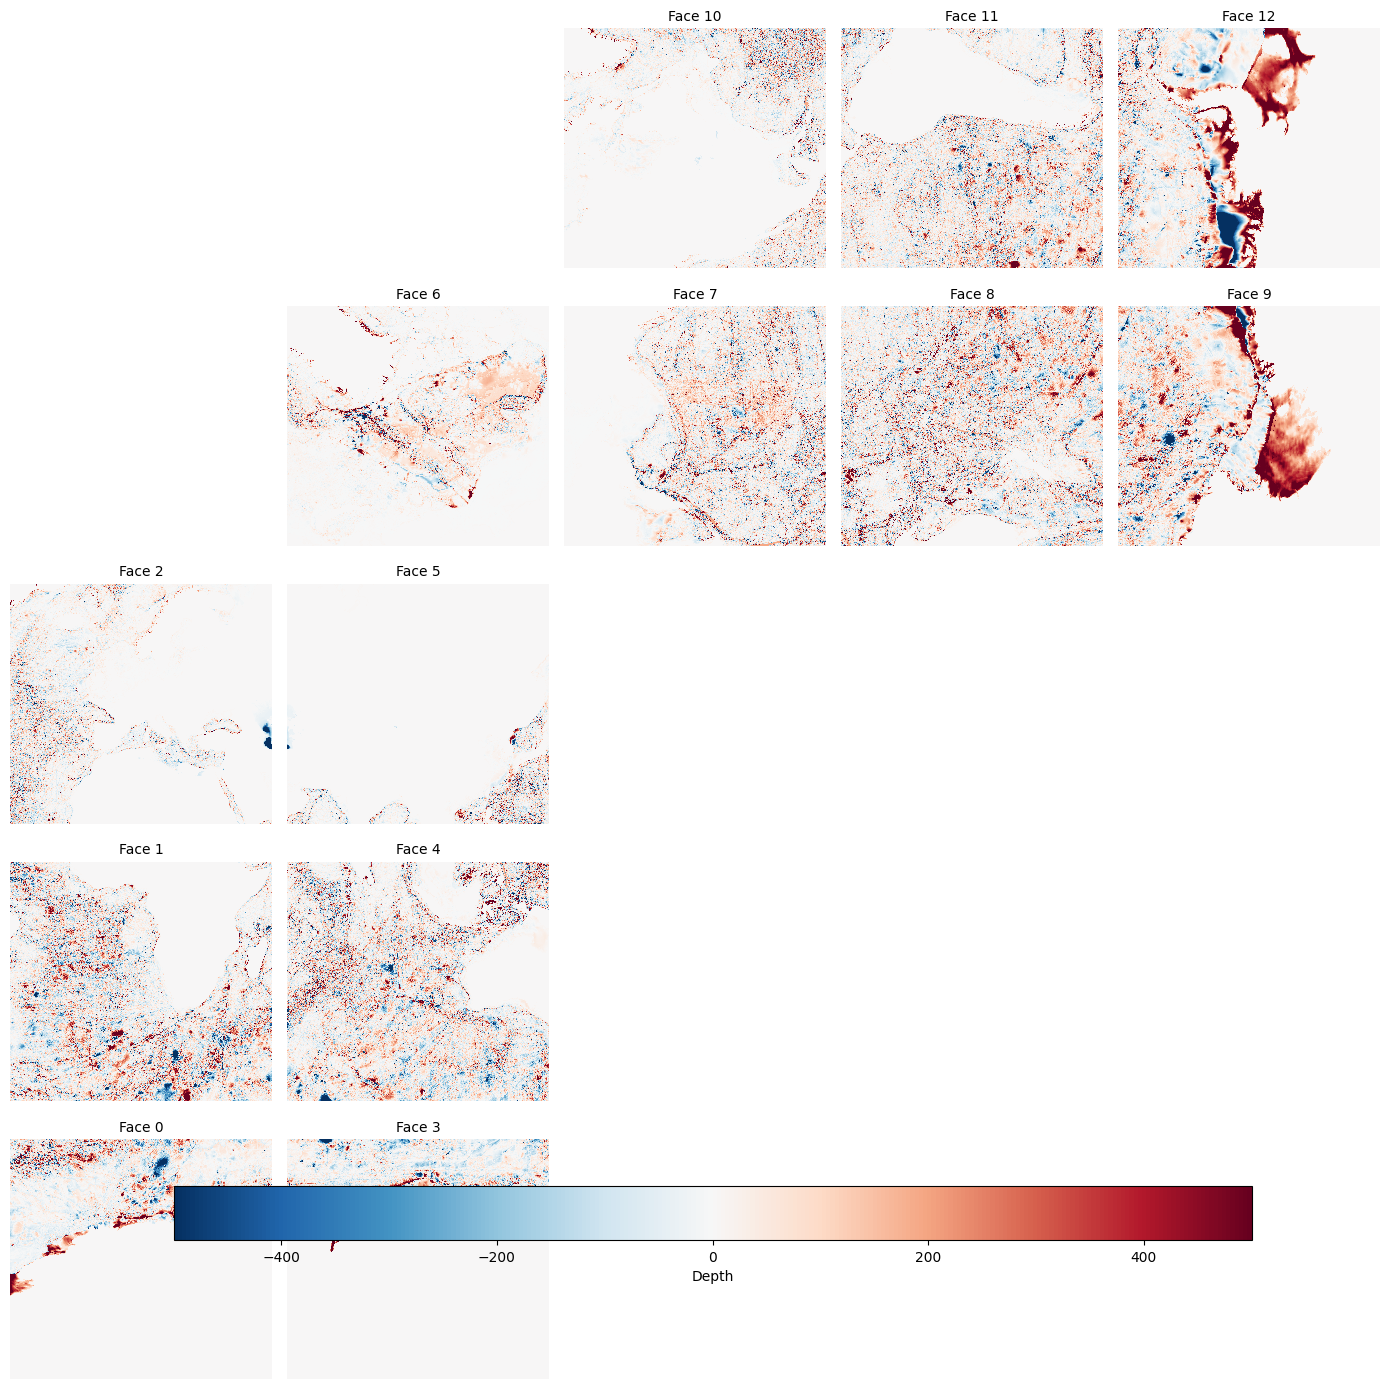

<Figure size 640x480 with 0 Axes>

In [17]:
# v2 horizontal grid vs the original LLC4320 grid the repo already uses (OSN kerchunk).
from dbof.llc4320_ingestion import get_raw_data
from dbof.global_dataset_creation.data_sources import OSN_ENDPOINT

grid_v1 = get_raw_data.get_remote_gridfile(OSN_ENDPOINT)

rows = []
for v in ["XC", "YC", "Depth", "rA", "dxC", "dyC", "dxG", "dyG", "rAz", "CS", "SN"]:
    if v not in grid_v1 or v not in grid:
        rows.append(dict(var=v, max_abs_diff=np.nan, note="missing on one side")); continue
    a, b = grid[v], grid_v1[v]
    if a.shape == b.shape:                      # subsample: full fields are ~1 GB each
        a = a[(slice(None),) + (slice(None, None, 8),) * (a.ndim - 1)]
        b = b[(slice(None),) + (slice(None, None, 8),) * (b.ndim - 1)]
    else:
        rows.append(dict(var=v, max_abs_diff=np.nan, note=f"shape {a.shape} vs {b.shape}")); continue
    d = float(np.nanmax(np.abs(a.values - b.values)))
    rows.append(dict(var=v, max_abs_diff=d, note=""))
cmp = pd.DataFrame(rows).set_index("var"); display(cmp)

same_xy = bool(cmp.loc[["XC", "YC"], "max_abs_diff"].max() < 1e-4)
check(5, "v2 XC/YC identical to original LLC4320 grid", same_xy, True,
      note="→ face_connections / COMODO metadata in dbof carry over unchanged")
check(5, "v2 CS/SN identical to original LLC4320 grid (float32 tolerance)",
      float(cmp.loc[["CS", "SN"], "max_abs_diff"].max()), ok=bool(cmp.loc[["CS", "SN"], "max_abs_diff"].max() < 1e-5))
check(5, "v2 Depth identical to original", float(cmp.loc["Depth", "max_abs_diff"]),
      ok=bool(cmp.loc["Depth", "max_abs_diff"] < 1e-3), note="bathymetry is what differs if the v2 run used a different topography")

# If Depth differs: how many cells, and where?  (land=0 in both; NaN ignored)
dD = (grid.Depth - grid_v1.Depth.values).compute()
n_diff = int((np.abs(dD) > 1.0).sum())
check(5, "cells where |Depth_v2 - Depth_v1| > 1 m", n_diff, note=f"of {dD.size}; {100*n_diff/dD.size:.3f} %")
if n_diff:
    per_face = (np.abs(dD) > 1.0).sum(("j", "i")).values
    print("differing cells per face:", dict(enumerate(per_face.tolist())))
    llc_plotting.plot_llc_faces_layout(dD, color_map="RdBu_r", vmin=-500, vmax=500)
    plt.suptitle("Depth_v2 − Depth_v1 (m)", y=0.92); plt.show()

## 6. The values — land NaN, ocean range, exact zeros

HOWTO: land is NaN; ocean values roughly −2.6 to 36.6 °C; about 0.0025 % of ocean
points hold exactly 0.0 (a known artefact, not a physical value). We check these on
the HOWTO's example hour, globally, and show the field.

In [18]:
theta = ds.Theta
mask  = grid.maskC.astype(bool) if "face" in grid.maskC.dims else None

nan_frac_global = float(theta.isnull().mean().compute())
if mask is not None:
    isnan = theta.isnull()
    land_nan  = float((isnan & ~mask).sum().compute() / (~mask).sum().compute())   # NaN fraction among land cells
    ocean_nan = float((isnan &  mask).sum().compute() /   mask.sum().compute())    # NaN fraction among ocean cells (should be ~0)
    n_wet_land = int((~isnan & ~mask).sum().compute())                             # finite Theta on land cells (should be 0)
    check(6, "finite Theta values on maskC==0 cells", n_wet_land, 0)
    check(6, "NaN fraction over maskC==0 (land)", round(land_nan, 6), ok=land_nan > 0.999)
    check(6, "NaN fraction over maskC==1 (ocean)", round(ocean_nan, 6), ok=ocean_nan < 1e-3)
print(f"global NaN fraction {nan_frac_global:.4f} (land ≈ 29 % of area, but faces 0/3/9/12 hold Antarctica)")

[PASS] finite Theta values on maskC==0 cells: observed=0  documented=0
[PASS] NaN fraction over maskC==0 (land): observed=1.0
[PASS] NaN fraction over maskC==1 (ocean): observed=0.0
global NaN fraction 0.4187 (land ≈ 29 % of area, but faces 0/3/9/12 hold Antarctica)


In [19]:
tmin, tmax = dask.compute(theta.min(), theta.max())
tmin, tmax = float(tmin), float(tmax)
check(6, "ocean minimum (°C), this hour", round(tmin, 2), expected=-2.6, ok=tmin >= -2.6 - 0.1,
      note="must not be colder than the documented record min; freezing point ≈ -1.9 (S=35) to -2.6 (brine)")
check(6, "ocean maximum (°C), this hour", round(tmax, 2), expected=36.6, ok=tmax <= 36.6 + 0.5,
      note="must not exceed the documented record max; a March hour will sit below it")
cold = theta < -2.6
print(f"{int(cold.sum().compute())} cells colder than -2.6 °C; per face:",
      dict(enumerate(cold.sum(("j", "i")).compute().values.tolist())))

n_ocean = int(theta.notnull().sum().compute())
n_zero  = int((theta == 0.0).sum().compute())
zero_pct = 100 * n_zero / n_ocean
check(6, "exact-zero ocean points (%)", round(zero_pct, 5), ok=zero_pct < 0.01, expected=0.0025)

[FAIL] ocean minimum (°C), this hour: observed=-3.39  documented=-2.6  (must not be colder than the documented record min; freezing point ≈ -1.9 (S=35) to -2.6 (brine))
[PASS] ocean maximum (°C), this hour: observed=32.9  documented=36.6  (must not exceed the documented record max; a March hour will sit below it)
4 cells colder than -2.6 °C; per face: {0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 2, 7: 2, 8: 0, 9: 0, 10: 0, 11: 0, 12: 0}
[PASS] exact-zero ocean points (%): observed=0.0  documented=0.0025


True

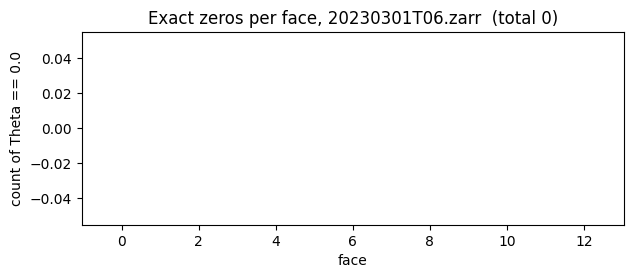

In [20]:
# Where are the exact zeros?  Transparent view of the artefact the HOWTO warns about.
zero_per_face = (theta == 0.0).sum(("j", "i")).compute().values
fig, ax = plt.subplots(figsize=(7, 2.5))
ax.bar(range(13), zero_per_face); ax.set_xlabel("face"); ax.set_ylabel("count of Theta == 0.0")
ax.set_title(f"Exact zeros per face, {STORE.rsplit('/',1)[-1]}  (total {n_zero})"); plt.show()

/Users/lahoffma/miniforge3/envs/fronts/lib/python3.12/site-packages/xmitgcm/llcreader/llcmodel.py:322: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  data = np.arange(ifac * coords.dims[vname])
/Users/lahoffma/miniforge3/envs/fronts/lib/python3.12/site-packages/xmitgcm/llcreader/llcmodel.py:324: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  data = np.arange(jfac * coords.dims[vname])


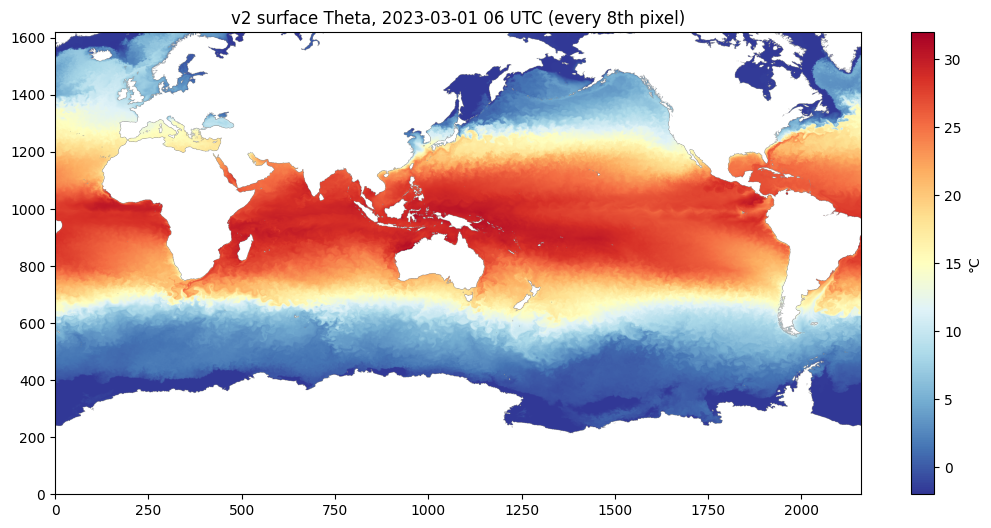

[PASS] faces_dataset_to_latlon stitches v2 Theta (repo routine): observed=0.569  (ocean fraction of stitched image; visual check above)


In [21]:
# Global SST for the example hour, stitched with the repo's own face→lat/lon routine
# (pixel re-arrangement, not interpolation).  This is the check "does it look like
# an ocean", which no statistic replaces.
from dbof.utils.faces_to_latlon import faces_dataset_to_latlon

try:
    ll = faces_dataset_to_latlon(xr.Dataset({"Theta": theta}), metric_vector_pairs=[])
    sst_ll = ll.Theta.compute()
    fig, ax = plt.subplots(figsize=(13, 6))
    im = ax.imshow(sst_ll.values[::8, ::8], origin="lower", cmap="RdYlBu_r", vmin=-2, vmax=32, aspect="auto")
    plt.colorbar(im, ax=ax, label="°C"); ax.set_title("v2 surface Theta, 2023-03-01 06 UTC (every 8th pixel)")
    plt.show()
    check(6, "faces_dataset_to_latlon stitches v2 Theta (repo routine)",
          round(float(np.isfinite(sst_ll.values[::8, ::8]).mean()), 3), ok=True, note="ocean fraction of stitched image; visual check above")
except Exception as e:
    check(6, "faces_dataset_to_latlon stitches v2 Theta (repo routine)", f"{type(e).__name__}: {e}", ok=False)

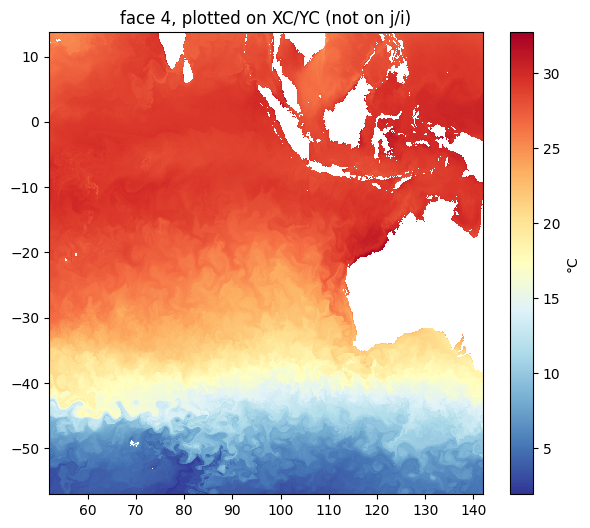

In [22]:
# One face at full resolution (face 4, North-East Pacific incl. Monterey Bay) — as in the HOWTO snippet.
sst = ds.Theta.isel(face=4); lon = grid.XC.isel(face=4); lat = grid.YC.isel(face=4)
fig, ax = plt.subplots(figsize=(7, 6))
pc = ax.pcolormesh(lon[::4, ::4], lat[::4, ::4], sst[::4, ::4], cmap="RdYlBu_r", shading="auto")
plt.colorbar(pc, ax=ax, label="°C"); ax.set_title("face 4, plotted on XC/YC (not on j/i)")
plt.show()

## 7. Reading v2 with the repo's own modules (`dbof`)

The claim we most need for the pipeline: the v2 stores can be read by the same
code path as the original `LLC4320_RAW/SURFACE` and `LLC4320_RAW/DEPTH` stores.
We go through each entry point and record exactly what works unchanged, what
needs a keyword, and what needs a rename.

In [23]:
from dbof.llc4320_ingestion.get_raw_data import (
    get_llc_timestep_data, get_llc_depth_gridfile, _llc_surf_storage_options)

# 7a. Hourly store through get_llc_timestep_data.
#     Only change: the function defaults to *credentialed* access for the Nautilus
#     endpoint; v2 is public, so pass anon=True through storage_options.
so = _llc_surf_storage_options(ENDPOINT, anon=True)
ds_dbof = get_llc_timestep_data(ENDPOINT, BUCKET, PREFIX, "2023-03-01 06:00:00",
                                vars_requested=["Theta"], storage_options=so)
check(7, "get_llc_timestep_data opens a v2 hour", "Theta" in ds_dbof, True,
      note="needs storage_options=_llc_surf_storage_options(ENDPOINT, anon=True)")
check(7, "get_llc_timestep_data dims", tuple(ds_dbof.Theta.dims), ("face", "j", "i"),
      note="default chunks dict mentions k=51; harmless because v2 has no k")

# values identical to the plain-xarray open
same = bool(np.array_equal(ds_dbof.Theta.isel(face=4, j=slice(2000, 2100), i=slice(2000, 2100)).values,
                           ds.Theta.isel(face=4, j=slice(2000, 2100), i=slice(2000, 2100)).values, equal_nan=True))
check(7, "dbof read == xarray read (sample block)", same, True)

LLC timestep data loaded: 20230301T06.zarr, vars=['Theta']
[PASS] get_llc_timestep_data opens a v2 hour: observed=True  documented=True  (needs storage_options=_llc_surf_storage_options(ENDPOINT, anon=True))
[PASS] get_llc_timestep_data dims: observed=('face', 'j', 'i')  documented=('face', 'j', 'i')  (default chunks dict mentions k=51; harmless because v2 has no k)
[PASS] dbof read == xarray read (sample block): observed=True  documented=True


True

In [24]:
# 7b. Grid through get_llc_depth_gridfile.  The repo selects a fixed list of names
#     (XC … hFacC, Z, Zl, Zu, Zp1, drF).  v2 uses hFacC_k0 and RC/RF/DRF/DRC instead,
#     so we expect some names to be silently dropped — record which.
import dbof.llc4320_ingestion.get_raw_data as _grd
_orig = _grd._llc_depth_storage_options
_grd._llc_depth_storage_options = lambda ep: {**_orig(ep), "anon": True}   # v2 is public
try:
    grid_dbof = get_llc_depth_gridfile(ENDPOINT, BUCKET, PREFIX)
    got = sorted(grid_dbof.data_vars)
    wanted = ['XC','YC','dxC','dyC','dxG','dyG','rAz','rA','Depth','hFacC','SN','CS','Z','Zl','Zu','Zp1','drF']
    missing = sorted(set(wanted) - set(got))
    check(7, "get_llc_depth_gridfile opens v2 grid.zarr", True, True, note="with anon=True patched in")
    check(7, "grid variables the repo asks for but v2 names differently", missing, [],
          note="hFacC→hFacC_k0, Z/Zl/Zu/Zp1/drF→RC/RF/DRF/DRC")
    check(7, "COMODO axis attrs attached (i, j, i_g, j_g present)",
          all(d in grid_dbof.dims for d in ("i", "j", "i_g", "j_g")), True)
except Exception as e:
    check(7, "get_llc_depth_gridfile opens v2 grid.zarr", f"{type(e).__name__}: {e}", ok=False)
finally:
    _grd._llc_depth_storage_options = _orig

[FAIL] get_llc_depth_gridfile opens v2 grid.zarr: observed="ValueError: grid store s3://llc4320-v2/SURFACE/grid.zarr is missing dimension 'j_g'; found ['face', 'i', 'j']"


/Users/lahoffma/projects/Sea-Meets-the-Stars/llc4320-native-grid-preprocessing/src/dbof/llc4320_ingestion/get_raw_data.py:592: UserWarning: The specified chunks separate the stored chunks along dimension "k" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  grid = xr.open_zarr(


In [25]:
# 7c. Minimal rename shim → process_llc4320_grid → xgcm Grid with face connections
#     → a native-grid tracer gradient of v2 Theta.  If this runs, the whole surface
#     pipeline can consume v2 with a ~5-line adapter.
from dbof.preprocessing.preproc_llc_core_data import process_llc4320_grid
from dbof.llc4320_ingestion.grid import set_xgcm_grid, COMODO_COORD_META
from dbof.utils.native_gradient import calculate_grad_squared_tracer

V2_TO_DBOF = {"hFacC_k0": "hFacC", "hFacS_k0": "hFacS", "hFacW_k0": "hFacW",
              "RC": "Z", "RF": "Zp1", "DRF": "drF", "DRC": "drC"}
g2 = grid.rename({k: v for k, v in V2_TO_DBOF.items() if k in grid})

# v2 stores every variable on (face, j, i).  The C-grid code needs the staggered
# variables on i_g / j_g (as the OSN kerchunk grid has them), so relabel per
# variable following MITgcm conventions.  Values are untouched; only dim names change.
STAGGER = {  # var -> (y-dim, x-dim)
    "XG": ("j_g", "i_g"), "YG": ("j_g", "i_g"), "rAz": ("j_g", "i_g"),
    "dxC": ("j", "i_g"), "rAw": ("j", "i_g"), "hFacW": ("j", "i_g"), "dyG": ("j", "i_g"),
    "dyC": ("j_g", "i"), "rAs": ("j_g", "i"), "hFacS": ("j_g", "i"), "dxG": ("j_g", "i"),
}
if "i_g" not in g2.dims:
    out = {}
    for v in g2.data_vars:
        da = g2[v]
        if v in STAGGER and set(da.dims) >= {"j", "i"}:
            yd, xd = STAGGER[v]
            da = da.rename({"j": yd, "i": xd}).drop_vars([yd, xd], errors="ignore")
        out[v] = da
    g2 = xr.Dataset(out, attrs=g2.attrs)
    g2 = g2.assign_coords(i_g=np.arange(g2.sizes["i_g"]), j_g=np.arange(g2.sizes["j_g"]))
    print("relabelled staggered variables onto i_g/j_g:", sorted(v for v in STAGGER if v in g2))

for dim, attrs in COMODO_COORD_META.items():
    if dim in g2.dims and "axis" not in g2[dim].attrs:
        g2 = g2.assign_coords({dim: g2[dim].assign_attrs(attrs)})

try:
    ds_grid = process_llc4320_grid(g2)
    xg = set_xgcm_grid(ds_grid, use_connections=True)
    check(7, "process_llc4320_grid + xgcm Grid(face_connections) on v2 grid", True, True,
          note=f"after renaming {sorted(k for k in V2_TO_DBOF if k in grid)} and relabelling staggered dims")
    print(xg)
except Exception as e:
    check(7, "process_llc4320_grid + xgcm Grid(face_connections) on v2 grid", f"{type(e).__name__}: {e}", ok=False)

relabelled staggered variables onto i_g/j_g: ['XG', 'YG', 'dxC', 'dxG', 'dyC', 'dyG', 'hFacS', 'hFacW', 'rAs', 'rAw', 'rAz']
[PASS] process_llc4320_grid + xgcm Grid(face_connections) on v2 grid: observed=True  documented=True  (after renaming ['DRC', 'DRF', 'RC', 'RF', 'hFacC_k0', 'hFacS_k0', 'hFacW_k0'] and relabelling staggered dims)
<xgcm.Grid>
Y Axis (not periodic, padding='fill'):
  * center   j --> left
  * left     j_g --> center
X Axis (not periodic, padding='fill'):
  * center   i --> left
  * left     i_g --> center


[PASS] native |∇Theta|² computes on v2 (face 4): observed=0.891  (fraction of finite cells; land is NaN)


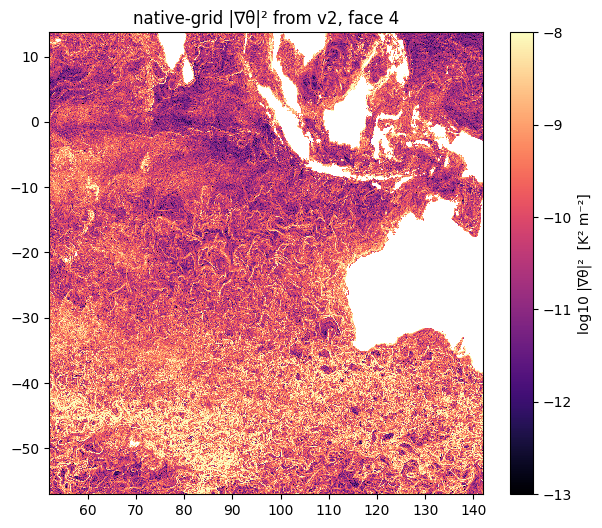

In [26]:
# |∇Theta|² on the native grid, evaluated for one face only (lazy graph covers all faces
# because of the seam exchange; we .compute() a single face to keep the read small).
try:
    gradT2 = calculate_grad_squared_tracer(ds.Theta, ds_grid, xg)
    g4 = gradT2.isel(face=4).compute()
    finite = float(np.isfinite(g4).mean())
    check(7, "native |∇Theta|² computes on v2 (face 4)", round(finite, 3), ok=finite > 0.3,
          note="fraction of finite cells; land is NaN")
    fig, ax = plt.subplots(figsize=(7, 6))
    pc = ax.pcolormesh(lon[::4, ::4], lat[::4, ::4], np.log10(g4[::4, ::4]), cmap="magma", vmin=-13, vmax=-8, shading="auto")
    plt.colorbar(pc, ax=ax, label="log10 |∇θ|²  [K² m⁻²]"); ax.set_title("native-grid |∇θ|² from v2, face 4"); plt.show()
except Exception as e:
    check(7, "native |∇Theta|² computes on v2 (face 4)", f"{type(e).__name__}: {e}", ok=False)

In [27]:
# 7d. Iteration numbers.  The repo converts dates↔iterations with the 2011-09-13 calendar.
#     v2 is a different run segment; the HOWTO says iteration numbers are NOT comparable.
from dbof.llc4320_ingestion import date_iterations as di
it_v2   = ds.attrs.get("selected_iteration")
it_v2   = int(it_v2) if it_v2 is not None else None
it_repo = di.mit_date_to_iteration("2023-03-01 06:00:00")
print(f"v2 store attr selected_iteration = {it_v2};  dbof calendar would give {it_repo}  (MAX_ITER in repo = {di.MAX_ITER})")
check(7, "v2 iteration ≠ dbof-calendar iteration (use timestamps, not iterations)",
      it_v2 != it_repo, True, note="confirms the HOWTO caveat; date_iterations must NOT be used for v2")

# consecutive hours: constant iteration stride?  (144 for a 25 s step)
ds_next = xr.open_zarr(f"{ROOT}/20230301T07.zarr", storage_options=OPTS)
stride = None
if it_v2 is not None and ds_next.attrs.get("selected_iteration") is not None:
    stride = int(ds_next.attrs["selected_iteration"]) - int(it_v2)
check(7, "iteration stride per hour", stride, note="144 ⇒ 25 s timestep as in the original run")

v2 store attr selected_iteration = 263400;  dbof calendar would give 14471136  (MAX_ITER in repo = 1495008)
[PASS] v2 iteration ≠ dbof-calendar iteration (use timestamps, not iterations): observed=True  documented=True  (confirms the HOWTO caveat; date_iterations must NOT be used for v2)
[INFO] iteration stride per hour: observed=300  (144 ⇒ 25 s timestep as in the original run)


## 8. The HOWTO's `wrangler` helpers

`open_range`, `extract_point`, `region_slices`, `open_grid` (and `nearest_index`),
run exactly as the HOWTO shows. Skipped if `wrangler` is not importable — the
`dbof` path in Section 7 does not depend on it.

In [28]:
try:
    from wrangler.ogcm import llc_v2_access as llc
    HAVE_WRANGLER = True
except Exception as e:
    HAVE_WRANGLER = False
    check(8, "wrangler.ogcm.llc_v2_access importable", f"{type(e).__name__}", ok=None, note="section skipped")

[INFO] wrangler.ogcm.llc_v2_access importable: observed='ModuleNotFoundError'  (section skipped)


In [29]:
if HAVE_WRANGLER:
    # "A date range as one dataset" — HOWTO says 169 hourly steps for 03-01 .. 03-08
    t0 = time.time()
    dsr = llc.open_range("2023-03-01", "2023-03-08")
    check(8, "open_range('2023-03-01','2023-03-08') time steps", dsr.sizes.get("time"), 169)
    check(8, "open_range dims", tuple(dsr.Theta.dims), ("time", "face", "j", "i"))
    check(8, "open_range is lazy (dask-backed)", dsr.Theta.chunks is not None, True, note=f"opened in {time.time()-t0:.1f}s")
    print("time axis:", dsr.time.values[0], "→", dsr.time.values[-1])

    mean4 = dsr.Theta.isel(face=4).mean("time").compute()
    fig, ax = plt.subplots(figsize=(7, 6))
    pc = ax.pcolormesh(lon[::4, ::4], lat[::4, ::4], mean4[::4, ::4], cmap="RdYlBu_r", shading="auto")
    plt.colorbar(pc, ax=ax, label="°C"); ax.set_title("week-mean Theta, face 4 (HOWTO example)"); plt.show()

In [30]:
if HAVE_WRANGLER:
    # "A time series at a location" — Monterey Bay
    pt = llc.extract_point(36.8, -121.9, "2023-03-01", "2023-04-01")
    check(8, "extract_point returns hourly series for March 2023", pt.sizes.get("time"), 31 * 24 + 1,
          ok=pt.sizes.get("time") in (31 * 24, 31 * 24 + 1), note="inclusive/exclusive end")
    dist = pt.attrs.get("distance_km")
    check(8, "extract_point distance_km attr (km)", dist, ok=dist is not None and dist < 3, note="cell spacing ~2 km here")
    pt.Theta.plot(figsize=(11, 3)); plt.title("SST at 36.8N, 121.9W — March 2023"); plt.show()

    # nearest_index on its own, if exposed
    if hasattr(llc, "nearest_index"):
        try:
            print("nearest_index(36.8, -121.9) →", llc.nearest_index(36.8, -121.9))
        except TypeError as e:
            print("nearest_index signature differs from a plain (lat, lon) call:", e)

In [31]:
if HAVE_WRANGLER:
    # "A latitude/longitude box" — California Current, verbatim from the HOWTO
    gridw = llc.open_grid()
    boxes = llc.region_slices(30, 40, -130, -115)
    check(8, "open_grid() variable count", len(gridw.data_vars), 23)
    check(8, "region_slices faces for California Current box", sorted(boxes), note="expect face 4 (and 5 or 7 if the box crosses a seam)")

    n_in_box = 0
    for face, (js, isl) in boxes.items():
        g   = gridw.isel(face=face, j=js, i=isl)
        dsb = llc.open_range("2023-07-01", "2023-07-02").isel(face=face, j=js, i=isl)
        sel = dsb.Theta.where((g.YC >= 30) & (g.YC <= 40) & (g.XC >= -130) & (g.XC <= -115))
        n_in_box += int(sel.isel(time=0).notnull().sum().compute())
        print(f"face {face}: j{js} i{isl}  → {sel.sizes}")
    check(8, "box selection yields ocean cells", n_in_box, ok=n_in_box > 1e5)

## 9. Performance claims

HOWTO: one request per hour for the time span (restrict time before space),
and land chunks are absent on disk (read back as NaN). We time a 24-hour open and
count the objects actually stored for a land-dominated face tile.

In [32]:
hours = [f"{ROOT}/{(stamps[0] + pd.Timedelta(hours=h)).strftime('%Y%m%dT%H')}.zarr" for h in range(24)]
t0 = time.time()
ds24 = xr.open_mfdataset(hours, engine="zarr", combine="nested", concat_dim="time",
                         storage_options=OPTS, parallel=True)
t24 = time.time() - t0
check(9, "open 24 hourly stores lazily (s)", round(t24, 1), ok=t24 < 60,
      note=f"{t24/24:.2f} s per hour → metadata cost scales with hours, not space")
print(ds24.Theta)

[PASS] open 24 hourly stores lazily (s): observed=3.7  (0.15 s per hour → metadata cost scales with hours, not space)
<xarray.DataArray 'Theta' (time: 24, face: 13, j: 4320, i: 4320)> Size: 23GB
dask.array<concatenate, shape=(24, 13, 4320, 4320), dtype=float32, chunksize=(1, 1, 720, 720), chunktype=numpy.ndarray>
Coordinates:
  * face     (face) int64 104B 0 1 2 3 4 5 6 7 8 9 10 11 12
  * j        (j) int64 35kB 0 1 2 3 4 5 6 ... 4313 4314 4315 4316 4317 4318 4319
  * i        (i) int64 35kB 0 1 2 3 4 5 6 ... 4313 4314 4315 4316 4317 4318 4319
Dimensions without coordinates: time
Attributes:
    long_name:           sea surface temperature (Theta, k=0)
    units:               degC
    source_file_prefix:  SST
    level:               0
    source_file:         SST.0000000720.data
    face_layout:         llc_faces


In [33]:
# Absent land chunks: count stored chunk objects vs the 13*6*6 = 468 possible tiles.
chunk_keys = [k for k in fs.find(f"{STORE}/Theta") if re.search(r"/c/\d+/\d+/\d+$", k) or re.search(r"/\d+\.\d+\.\d+$", k)]
n_possible = 13 * 6 * 6
check(9, "stored Theta chunk objects / possible", f"{len(chunk_keys)} / {n_possible}",
      ok=0 < len(chunk_keys) < n_possible, note="fewer than 468 ⇒ all-land tiles are not written")

# and the stored ones really are the ocean tiles: tile-level ocean fraction from maskC
tile_ocean = grid.maskC.astype(float).coarsen(j=720, i=720).mean().compute()   # (13, 6, 6)
n_ocean_tiles = int((tile_ocean > 0).sum())
check(9, "tiles with any ocean (from maskC)", n_ocean_tiles, len(chunk_keys),
      note="should equal the number of stored chunk objects")

[PASS] stored Theta chunk objects / possible: observed='366 / 468'  (fewer than 468 ⇒ all-land tiles are not written)
[PASS] tiles with any ocean (from maskC): observed=366  documented=366  (should equal the number of stored chunk objects)


True

## 10. Remaining caveats

* Times are instantaneous UTC snapshots, not hourly means — we can't test this from
  the data alone, but we can show that consecutive hours differ at the level expected
  of snapshots (sub-K hourly change away from fronts), and record it as INFO.
* Exact zeros — measured in Section 6.
* Iteration numbers — Section 7d.

[INFO] |ΔTheta| between consecutive hours, face 4: p50 / p99 / p99.99 (K): observed=[0.0438, 0.1336, 0.5809]  (snapshot-to-snapshot change; INFO)


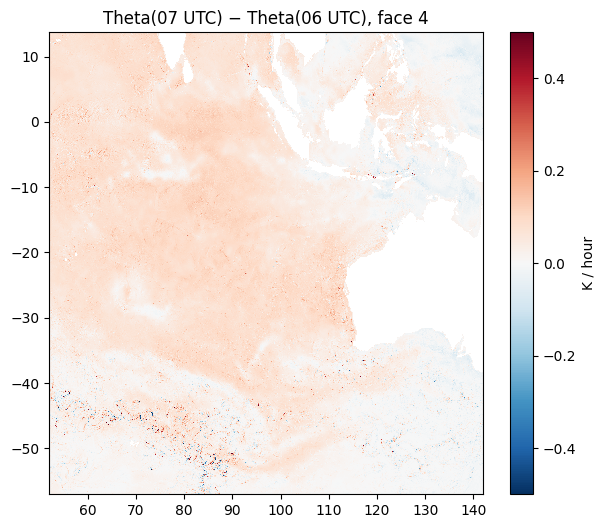

In [34]:
d1 = (ds_next.Theta - ds.Theta).isel(face=4)
d1v = d1.compute().values
q = np.nanpercentile(np.abs(d1v), [50, 99, 99.99])
check(10, "|ΔTheta| between consecutive hours, face 4: p50 / p99 / p99.99 (K)",
      [round(float(x), 4) for x in q], note="snapshot-to-snapshot change; INFO")
fig, ax = plt.subplots(figsize=(7, 6))
pc = ax.pcolormesh(lon[::4, ::4], lat[::4, ::4], d1v[::4, ::4], cmap="RdBu_r", vmin=-0.5, vmax=0.5, shading="auto")
plt.colorbar(pc, ax=ax, label="K / hour"); ax.set_title("Theta(07 UTC) − Theta(06 UTC), face 4"); plt.show()

## 11. Looking ahead: the vertical axis (173 levels vs the repo's 51-of-90)

Surface-only today, but `grid.zarr` already ships the v2 vertical axis. The repo's
DEPTH pipeline (`docs/Grid.md`) assumes the original LLC4320 column: 90 levels,
top 51 kept (to ~969 m), names `Z Zl Zu Zp1 drF`, chunk `k=51`. Here is exactly how
v2 differs, so the DEPTH adapter can be planned rather than discovered.

In [35]:
# Original vertical axis, from the OSN grid the repo already reads (Section 5).
# The OSN kerchunk grid is surface-only (k=0): its Z/drF are scalars, so no vertical axis there.
z1 = np.atleast_1d(grid_v1["Z"].values) if "Z" in grid_v1 else None
drf1 = np.atleast_1d(grid_v1["drF"].values) if "drF" in grid_v1 else None
if z1 is None or z1.size < 2:
    print(f"OSN grid carries only the surface level (Z={z1}); trying the repo's DEPTH grid.zarr (credentialed) for the 51-level axis")
    z1 = drf1 = None
    try:
        from dbof.global_dataset_creation.data_sources import LLC_DEPTH_SOURCE
        gD = get_llc_depth_gridfile(LLC_DEPTH_SOURCE["s3_endpoint"], LLC_DEPTH_SOURCE["bucket"], LLC_DEPTH_SOURCE["folder"])
        z1, drf1 = gD["Z"].values, gD["drF"].values
        print(f"loaded {z1.size}-level axis from dbof/LLC4320_RAW/DEPTH/grid.zarr")
    except Exception as e:
        print("DEPTH grid not available here:", type(e).__name__, "— v1 columns will be blank; see docs/Grid.md for the 51-level table")

rows = []
for k in range(min(len(rc), 60)):
    rows.append(dict(k=k, v2_RC_m=round(-rc[k], 2), v2_DRF_m=round(drf[k], 2),
                     v1_Z_m=(round(-z1[k], 2) if z1 is not None and k < len(z1) else None),
                     v1_drF_m=(round(drf1[k], 2) if drf1 is not None and k < len(drf1) else None)))
vert = pd.DataFrame(rows).set_index("k")
display(vert.head(60))

check(11, "v2 levels", len(rc), note=f"vs {len(z1) if z1 is not None else '?'} in original (repo keeps top 51)")
if z1 is not None:
    nshare = int(np.sum(np.isclose(-rc[:len(z1)], -z1, atol=0.05)))
    check(11, "leading levels identical to original axis", nshare,
          note="0 ⇒ v2 is a genuinely new vertical grid; the repo's k=51 cut and docs/Grid.md table will not apply")
    k969 = int(np.searchsorted(-rc, 969.0))
    check(11, "v2 level index reaching the repo's 969 m cut", k969, note="replaces k=51 in llc_depth_timestep_chunks")

OSN grid carries only the surface level (Z=[-0.5]); trying the repo's DEPTH grid.zarr (credentialed) for the 51-level axis


/Users/lahoffma/projects/Sea-Meets-the-Stars/llc4320-native-grid-preprocessing/src/dbof/llc4320_ingestion/get_raw_data.py:592: UserWarning: The specified chunks separate the stored chunks along dimension "k" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  grid = xr.open_zarr(
/Users/lahoffma/projects/Sea-Meets-the-Stars/llc4320-native-grid-preprocessing/src/dbof/llc4320_ingestion/get_raw_data.py:592: UserWarning: The specified chunks separate the stored chunks along dimension "k_l" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  grid = xr.open_zarr(


LLC_DEPTH grid file loaded from s3://dbof/LLC4320_RAW/DEPTH/grid.zarr.
loaded 51-level axis from dbof/LLC4320_RAW/DEPTH/grid.zarr


,v2_RC_m,v2_DRF_m,v1_Z_m,v1_drF_m
k,,,,
0,1.820000,3.63,0.500000,1.000000
1,5.480000,3.69,1.570000,1.140000
2,9.200000,3.76,2.790000,1.300000
3,12.990000,3.82,4.180000,1.490000
4,16.840000,3.88,5.780000,1.700000
5,20.760000,3.95,7.600000,1.930000
6,24.740000,4.01,9.660000,2.200000
7,28.790001,4.08,12.010000,2.500000
8,32.900002,4.14,14.680000,2.840000


[INFO] v2 levels: observed=173  (vs 51 in original (repo keeps top 51))
[INFO] leading levels identical to original axis: observed=0  (0 ⇒ v2 is a genuinely new vertical grid; the repo's k=51 cut and docs/Grid.md table will not apply)
[INFO] v2 level index reaching the repo's 969 m cut: observed=89  (replaces k=51 in llc_depth_timestep_chunks)


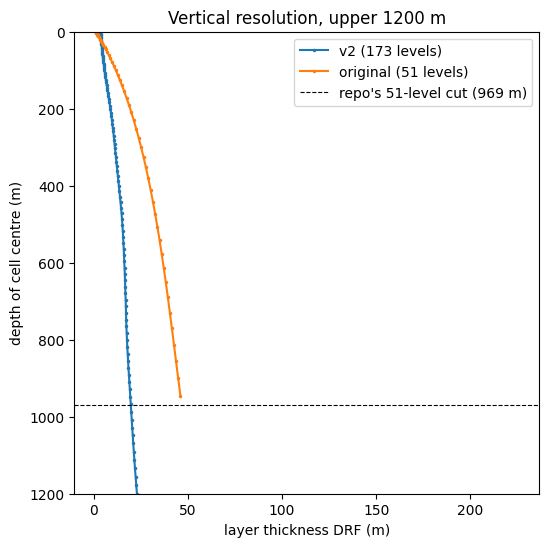

In [36]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(drf, -rc, ".-", ms=3, label=f"v2 ({len(rc)} levels)")
if z1 is not None and drf1 is not None:
    ax.plot(drf1, -z1, ".-", ms=3, label=f"original ({len(z1)} levels)")
    ax.axhline(969, color="k", lw=0.8, ls="--", label="repo's 51-level cut (969 m)")
ax.set_ylim(1200, 0); ax.set_xlabel("layer thickness DRF (m)"); ax.set_ylabel("depth of cell centre (m)")
ax.legend(); ax.set_title("Vertical resolution, upper 1200 m"); plt.show()

## 12. Summary

Every claim, its documented value, what we measured, and the verdict.
`FAIL` rows are the ones to raise with X before the next variables are pulled.

In [37]:
summary = pd.DataFrame(RESULTS)[["section", "status", "claim", "documented", "observed", "note"]]
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 200)
display(summary)

counts = summary.status.value_counts()
print(counts.to_dict())
fails = summary[summary.status == "FAIL"]
print("\nFAILED CHECKS:" if len(fails) else "\nNo failed checks.")
for _, r in fails.iterrows():
    print(f"  §{r.section}: {r.claim} — observed {r.observed!r}, documented {r.documented!r}")

,section,status,claim,documented,observed,note
0,1,PASS,anonymous listing works,True,True,
1,1,PASS,grid.zarr present,True,True,
2,1,INFO,non-hourly objects in prefix,None,[grid.zarr],expect only grid.zarr
3,1,PASS,bucket is read-only for anonymous clients,True,True,
4,1,PASS,path-style addressing is required (virtual-hosted fails),True,True,INFO only if your DNS happens to resolve bucket.host
...,...,...,...,...,...,...
56,9,PASS,tiles with any ocean (from maskC),366,366,should equal the number of stored chunk objects
57,10,INFO,"|ΔTheta| between consecutive hours, face 4: p50 / p99 / p99.99 (K)",None,"[0.0438, 0.1336, 0.5809]",snapshot-to-snapshot change; INFO
58,11,INFO,v2 levels,None,173,vs 51 in original (repo keeps top 51)
59,11,INFO,leading levels identical to original axis,None,0,0 ⇒ v2 is a genuinely new vertical grid; the repo's k=51 cut and docs/Grid.m...


{'PASS': 46, 'INFO': 8, 'FAIL': 7}

FAILED CHECKS:
  §2: number of hourly stores — observed 9502, documented 9692
  §2: last snapshot (UTC) — observed '2024-01-31 23:00:00+00:00', documented '2024-02-08 20:00:00+00:00'
  §2: hourly, no gaps — observed False, documented True
  §5: v2 CS/SN identical to original LLC4320 grid (float32 tolerance) — observed 1.0, documented None
  §5: v2 Depth identical to original — observed 3082.41357421875, documented None
  §6: ocean minimum (°C), this hour — observed -3.39, documented -2.6
  §7: get_llc_depth_gridfile opens v2 grid.zarr — observed "ValueError: grid store s3://llc4320-v2/SURFACE/grid.zarr is missing dimension 'j_g'; found ['face', 'i', 'j']", documented None


In [38]:
# Keep a copy next to the notebook so the verdict is reviewable without re-running.
out = "verify_llc4320_v2_howto_results.csv"
summary.to_csv(out, index=False); print("wrote", out)

wrote verify_llc4320_v2_howto_results.csv
